In [1]:
# ============================================================
# 1. Setup
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [5]:
# ============================================================
# 2. Daten laden
# ============================================================

df_raw = pd.read_excel(
    "C:\\Users\\janis\\OneDrive - FHNW\\P-pro2Db_Ausfälle-in-Schlammtrockungsanlage_M365 - STRAG AG\\Data\\Prozess\\FHNW_PLS_Data_2026-03.xlsx"
)

df_raw.head(6)

,Datum,LI-117,LISA-103,TI-158,TI-165,TI-157,PCA-414,PA-411,TIZA-164,MI-156,TIC-160
0,NaT,Niveau Schubboden,Füllstand Verteiler,Temperatur Heizwasser VL,Temperatur Heizwasser RL nach W002,Temperatur Heizwasser RL,Druck Ausgleichsgefäss,Druck Heisswasser,Temperatur Abluft,Feuchte Abluft,Temperatur Kühlwasser
1,NaT,%,m,°C,°C,°C,bar,bar,°C,rF,°C
2,NaT,Mittel,Mittel,Mittel,Mittel,Mittel,Mittel,Mittel,Mittel,Mittel,Mittel
3,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-03-01,8,0.53,129.5,102.8,111.7,5,4.5,82.3,32.5,23.4
5,2026-03-01,8,0.52,129.3,102.8,111.8,5,4.5,82.3,32.5,23.4


In [6]:
df_raw.head(15)

,Datum,LI-117,LISA-103,TI-158,TI-165,TI-157,PCA-414,PA-411,TIZA-164,MI-156,TIC-160
0,NaT,Niveau Schubboden,Füllstand Verteiler,Temperatur Heizwasser VL,Temperatur Heizwasser RL nach W002,Temperatur Heizwasser RL,Druck Ausgleichsgefäss,Druck Heisswasser,Temperatur Abluft,Feuchte Abluft,Temperatur Kühlwasser
1,NaT,%,m,°C,°C,°C,bar,bar,°C,rF,°C
2,NaT,Mittel,Mittel,Mittel,Mittel,Mittel,Mittel,Mittel,Mittel,Mittel,Mittel
3,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-03-01 00:00:00,8,0.53,129.5,102.8,111.7,5,4.5,82.3,32.5,23.4
5,2026-03-01 00:00:00,8,0.52,129.3,102.8,111.8,5,4.5,82.3,32.5,23.4
6,2026-03-01 00:00:00,8,0.5,129.2,102.9,111.8,5,4.5,82.3,32.5,23.4
7,2026-03-01 00:00:00,6,0.5,129.1,103,111.8,5,4.5,82.3,32.5,23.4
8,2026-03-01 00:00:00,8,0.52,128.9,103,111.8,5,4.5,82.3,32.5,23.4
9,2026-03-01 00:00:00,9,0.52,128.8,103.1,111.8,5,4.5,82.3,32.5,23.4


In [3]:
# ============================================================
# Parameter-Legende aus Metadaten erstellen
# ============================================================

parameter_legend = df_raw.iloc[0:3].T.reset_index()

parameter_legend.columns = ["Parameter", "Beschreibung", "Einheit", "Aggregation"]

parameter_legend

,Parameter,Beschreibung,Einheit,Aggregation
0,Datum,NaT,NaT,NaT
1,LI-117,Niveau Schubboden,%,Mittel
2,LISA-103,Füllstand Verteiler,m,Mittel
3,TI-158,Temperatur Heizwasser VL,°C,Mittel
4,TI-165,Temperatur Heizwasser RL nach W002,°C,Mittel
5,TI-157,Temperatur Heizwasser RL,°C,Mittel
6,PCA-414,Druck Ausgleichsgefäss,bar,Mittel
7,PA-411,Druck Heisswasser,bar,Mittel
8,TIZA-164,Temperatur Abluft,°C,Mittel
9,MI-156,Feuchte Abluft,rF,Mittel


In [7]:
df = df_raw.iloc[4:].reset_index(drop=True)

df.head(10)

,Datum,LI-117,LISA-103,TI-158,TI-165,TI-157,PCA-414,PA-411,TIZA-164,MI-156,TIC-160
0,2026-03-01 00:00:00,8,0.53,129.5,102.8,111.7,5,4.5,82.3,32.5,23.4
1,2026-03-01 00:00:00,8,0.52,129.3,102.8,111.8,5,4.5,82.3,32.5,23.4
2,2026-03-01 00:00:00,8,0.5,129.2,102.9,111.8,5,4.5,82.3,32.5,23.4
3,2026-03-01 00:00:00,6,0.5,129.1,103,111.8,5,4.5,82.3,32.5,23.4
4,2026-03-01 00:00:00,8,0.52,128.9,103,111.8,5,4.5,82.3,32.5,23.4
5,2026-03-01 00:00:00,9,0.52,128.8,103.1,111.8,5,4.5,82.3,32.5,23.4
6,2026-03-01 00:01:00,8,0.52,128.6,103.1,111.8,5,4.5,82.3,32.5,23.4
7,2026-03-01 00:01:00,8,0.53,128.5,103.2,111.7,5,4.5,82.3,32.5,23.4
8,2026-03-01 00:01:00,9,0.59,128.4,103.3,111.7,5,4.5,82.3,32.5,23.4
9,2026-03-01 00:01:00,8,0.59,128.2,103.3,111.6,5,4.5,82.3,32.6,23.4


In [9]:
# ============================================================
# Zeitstempel korrigieren: 10-Sekunden-Werte rekonstruieren
# ============================================================

df = df.copy()

# Sicherstellen, dass Datum datetime ist
df["Datum"] = pd.to_datetime(df["Datum"])

# Reihenfolge sicherstellen
df = df.sort_values("Datum").reset_index(drop=True)

# Laufende Nummer innerhalb jeder Minute: 0, 1, 2, 3, 4, 5
idx_in_minute = df.groupby("Datum").cumcount()

# Sekunden ergänzen: 0, 10, 20, 30, 40, 50
df["Datum_korrigiert"] = df["Datum"] + pd.to_timedelta(idx_in_minute * 10, unit="s")

# Optional: alte Datumsspalte ersetzen
df["Datum"] = df["Datum_korrigiert"]
df = df.drop(columns="Datum_korrigiert")

df.tail(10)

,Datum,LI-117,LISA-103,TI-158,TI-165,TI-157,PCA-414,PA-411,TIZA-164,MI-156,TIC-160
267464,2026-03-31 23:57:20,16,0.57,139.4,110.7,120,5.2,4.8,91,26,19.4
267465,2026-03-31 23:57:30,16,0.57,139.4,110.7,120,5.3,4.8,91,25.9,19.4
267466,2026-03-31 23:57:40,17,0.53,139.4,110.8,120,5.2,4.8,91,25.8,19.4
267467,2026-03-31 23:57:50,16,0.51,139.4,110.8,120,5.2,4.8,91.1,25.8,19.3
267468,2026-03-31 23:58:00,16,0.5,139.4,110.8,119.9,5.3,4.8,91.1,25.8,19.4
267469,2026-03-31 23:58:10,16,0.5,139.4,110.8,119.9,5.2,4.8,91.1,25.8,19.3
267470,2026-03-31 23:58:20,15,0.57,139.5,110.8,119.9,5.2,4.8,91.1,25.8,19.4
267471,2026-03-31 23:58:30,16,0.5,139.4,110.8,120,5.3,4.8,91.1,25.8,19.4
267472,2026-03-31 23:58:40,17,0.5,139.4,110.8,119.9,5.2,4.8,91.1,25.8,19.4
267473,2026-03-31 23:58:50,15,0.55,139.5,110.8,119.9,5.2,4.8,91.1,25.8,19.3


In [10]:
# ============================================================
# 3. Erster Überblick
# ============================================================

print(f"Zeilen: {df.shape[0]}")
print(f"Spalten: {df.shape[1]}")

df.info()

Zeilen: 267474
Spalten: 11
<class 'pandas.DataFrame'>
RangeIndex: 267474 entries, 0 to 267473
Data columns (total 11 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datum     267474 non-null  datetime64[us]
 1   LI-117    267474 non-null  object        
 2   LISA-103  267474 non-null  object        
 3   TI-158    267474 non-null  object        
 4   TI-165    267474 non-null  object        
 5   TI-157    267474 non-null  object        
 6   PCA-414   267474 non-null  object        
 7   PA-411    267474 non-null  object        
 8   TIZA-164  267474 non-null  object        
 9   MI-156    267474 non-null  object        
 10  TIC-160   267474 non-null  object        
dtypes: datetime64[us](1), object(10)
memory usage: 22.4+ MB


In [11]:
exclude_cols = ["Datum"]

df = df.copy()

for col in df.columns:
    if col in exclude_cols:
        continue

    converted = pd.to_numeric(df[col], errors="coerce")

    # Nur ersetzen, wenn die Spalte nach der Umwandlung nicht komplett leer wäre
    if converted.notna().sum() > 0:
        df[col] = converted

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 267474 entries, 0 to 267473
Data columns (total 11 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datum     267474 non-null  datetime64[us]
 1   LI-117    267474 non-null  int64         
 2   LISA-103  267474 non-null  float64       
 3   TI-158    267474 non-null  float64       
 4   TI-165    267474 non-null  float64       
 5   TI-157    267474 non-null  float64       
 6   PCA-414   267474 non-null  float64       
 7   PA-411    267474 non-null  float64       
 8   TIZA-164  267474 non-null  float64       
 9   MI-156    267474 non-null  float64       
 10  TIC-160   267474 non-null  float64       
dtypes: datetime64[us](1), float64(9), int64(1)
memory usage: 22.4 MB


In [12]:
df.head()

,Datum,LI-117,LISA-103,TI-158,TI-165,TI-157,PCA-414,PA-411,TIZA-164,MI-156,TIC-160
0,2026-03-01 00:00:00,8,0.53,129.5,102.8,111.7,5.0,4.5,82.3,32.5,23.4
1,2026-03-01 00:00:10,8,0.52,129.3,102.8,111.8,5.0,4.5,82.3,32.5,23.4
2,2026-03-01 00:00:20,8,0.50,129.2,102.9,111.8,5.0,4.5,82.3,32.5,23.4
3,2026-03-01 00:00:30,6,0.50,129.1,103.0,111.8,5.0,4.5,82.3,32.5,23.4
4,2026-03-01 00:00:40,8,0.52,128.9,103.0,111.8,5.0,4.5,82.3,32.5,23.4


In [13]:
df.describe(include="all").T

,count,mean,min,25%,50%,75%,max,std
Datum,267474,2026-03-16 11:34:59.247067,2026-03-01 00:00:00,2026-03-08 17:44:42.500000,2026-03-16 11:29:25,2026-03-24 05:14:07.500000,2026-03-31 23:58:50,NaN
LI-117,267474.0,12.543238,-2.0,9.0,12.0,16.0,87.0,4.073
LISA-103,267474.0,0.473787,0.17,0.43,0.47,0.51,0.79,0.063887
TI-158,267474.0,126.533811,36.8,133.7,138.5,139.3,144.5,29.265094
TI-165,267474.0,101.691983,35.2,106.3,109.4,110.6,121.5,20.506706
TI-157,267474.0,109.463397,36.1,114.7,118.0,119.5,135.7,23.008145
PCA-414,267474.0,4.968183,3.3,4.9,5.0,5.2,5.5,0.380716
PA-411,267474.0,4.495507,2.8,4.4,4.6,4.7,5.1,0.369022
TIZA-164,267474.0,80.110598,31.9,82.3,84.4,87.5,102.4,15.345271
MI-156,267474.0,30.840962,-13.6,28.0,31.2,33.5,100.0,5.037312


In [14]:
# ============================================================
# 5. Spaltentypen trennen
# ============================================================

num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerische Spalten:", num_cols)
print("Kategorische Spalten:", cat_cols)

Numerische Spalten: ['LI-117', 'LISA-103', 'TI-158', 'TI-165', 'TI-157', 'PCA-414', 'PA-411', 'TIZA-164', 'MI-156', 'TIC-160']
Kategorische Spalten: []


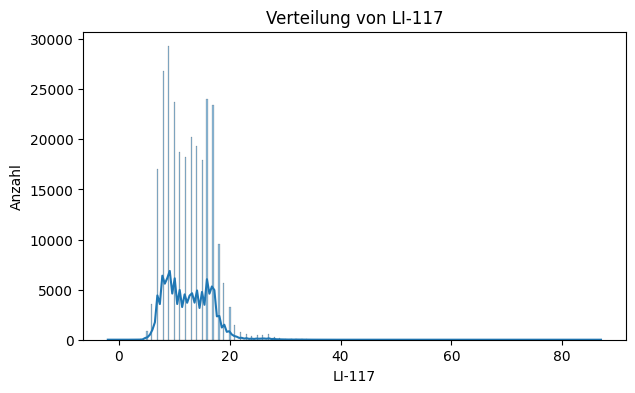

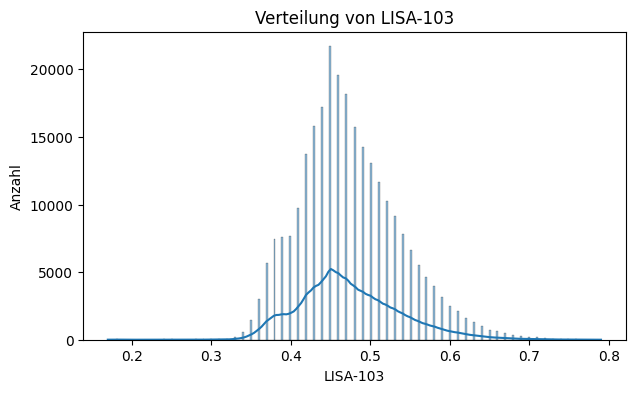

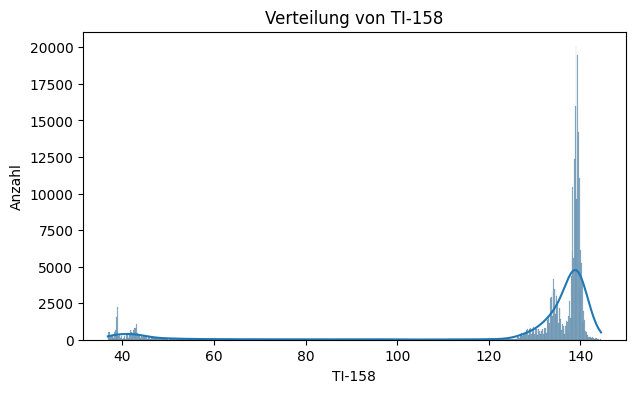

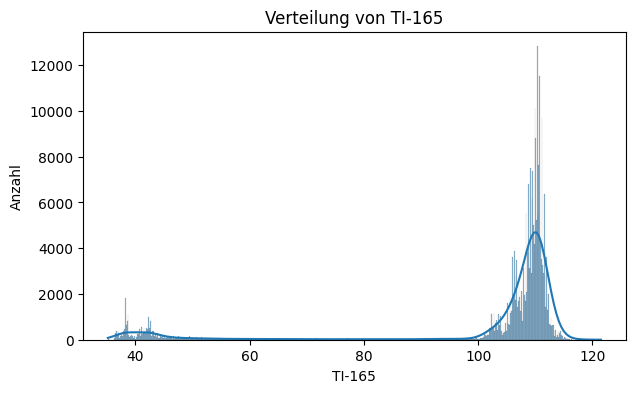

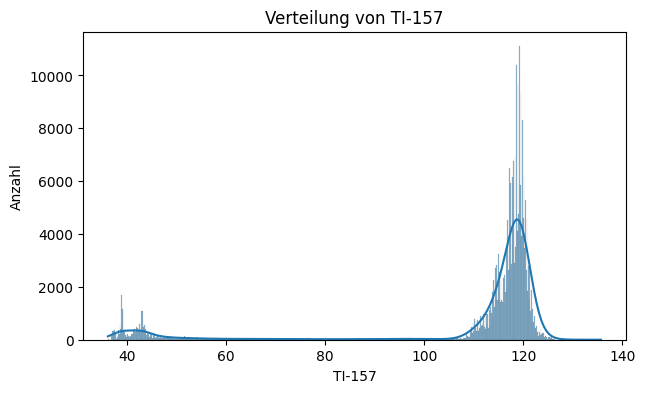

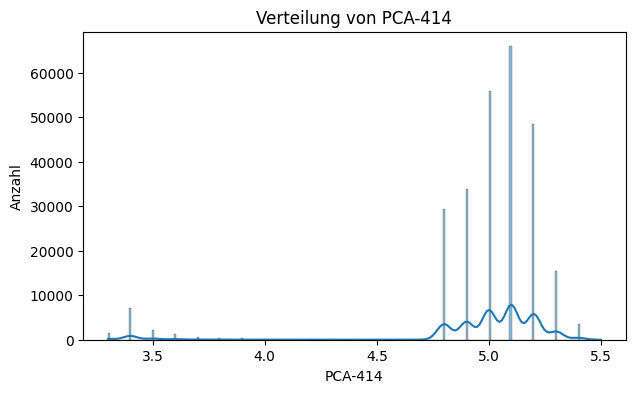

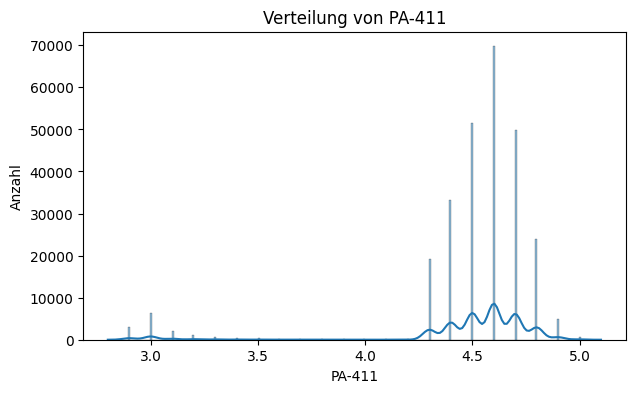

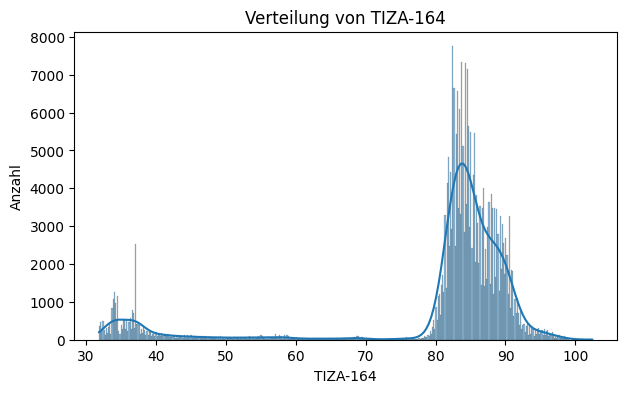

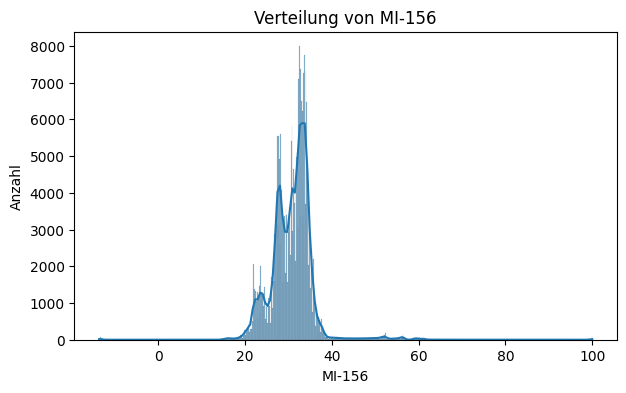

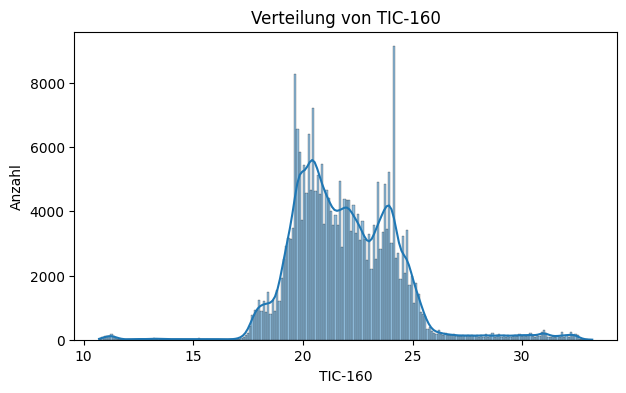

In [15]:
# ============================================================
# 6. Univariate Analyse: Numerische Variablen
# ============================================================

for col in num_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f"Verteilung von {col}")
    plt.xlabel(col)
    plt.ylabel("Anzahl")
    plt.show()

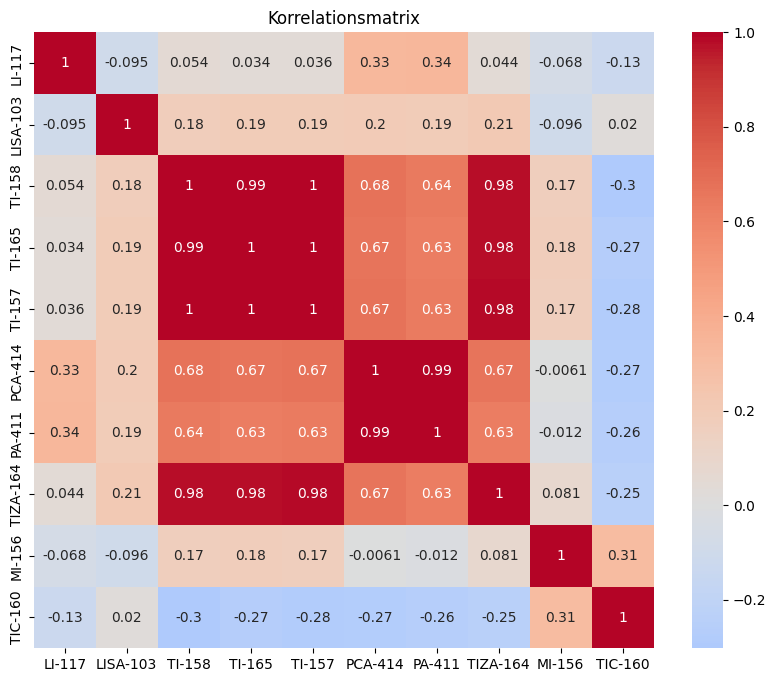

In [16]:
# ============================================================
# 8. Korrelationen
# ============================================================

corr = df[num_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Korrelationsmatrix")
plt.show()

In [17]:
# ============================================================
# 8.1 Stärkste Korrelationen anzeigen
# ============================================================

corr_pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))  # doppelte Paare entfernen
    .stack()
    .reset_index()
)

corr_pairs.columns = ["feature_1", "feature_2", "correlation"]

corr_pairs["abs_correlation"] = corr_pairs["correlation"].abs()

corr_pairs = corr_pairs.sort_values("abs_correlation", ascending=False)

corr_pairs.head(10)

,feature_1,feature_2,correlation,abs_correlation
34,TI-165,TI-157,0.999068,0.999068
24,TI-158,TI-157,0.996496,0.996496
23,TI-158,TI-165,0.994824,0.994824
56,PCA-414,PA-411,0.993109,0.993109
47,TI-157,TIZA-164,0.979971,0.979971
37,TI-165,TIZA-164,0.978688,0.978688
27,TI-158,TIZA-164,0.976033,0.976033
25,TI-158,PCA-414,0.676878,0.676878
45,TI-157,PCA-414,0.670098,0.670098
35,TI-165,PCA-414,0.667574,0.667574


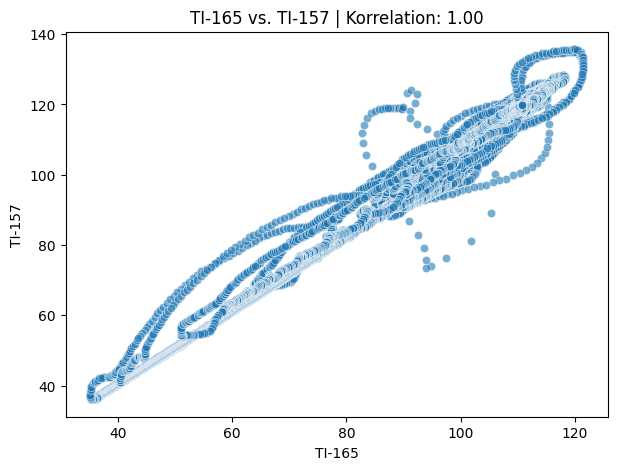

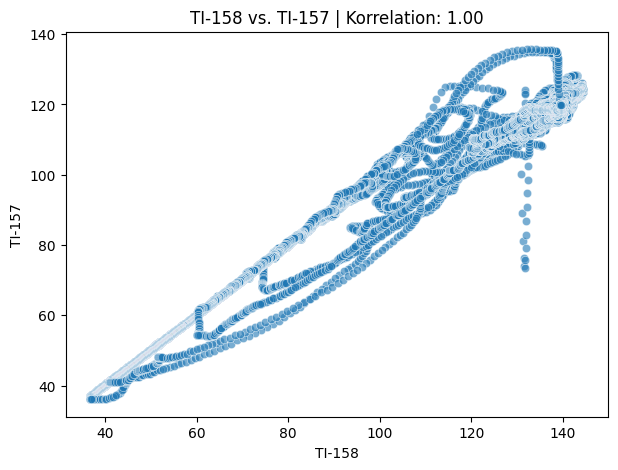

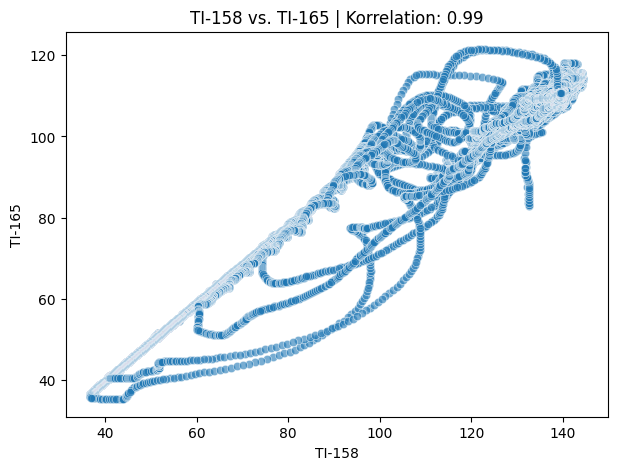

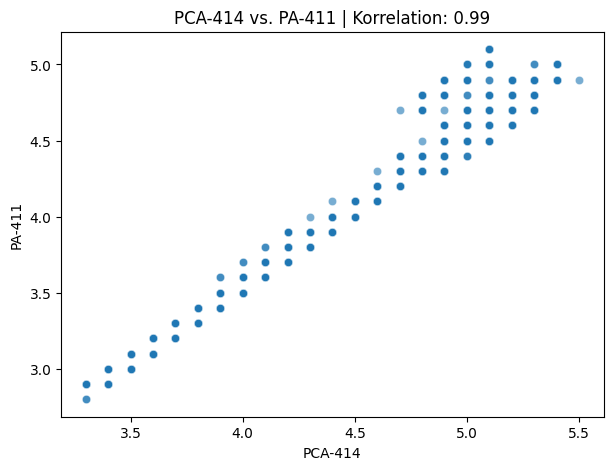

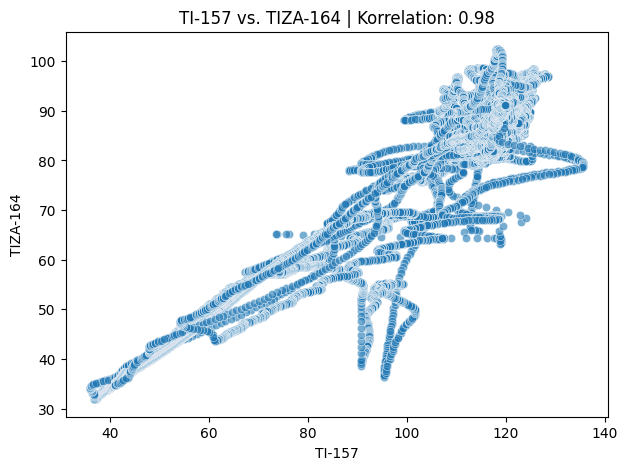

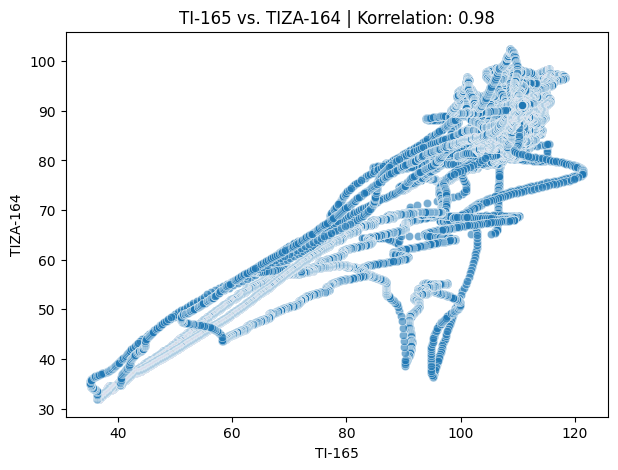

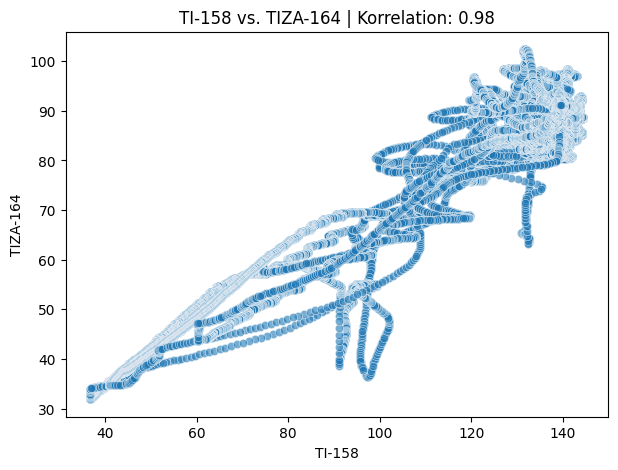

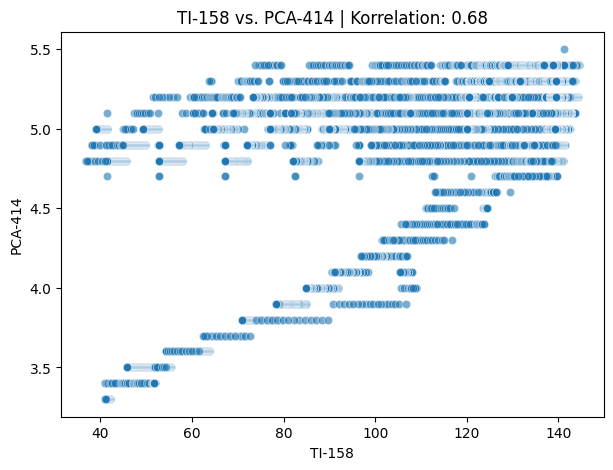

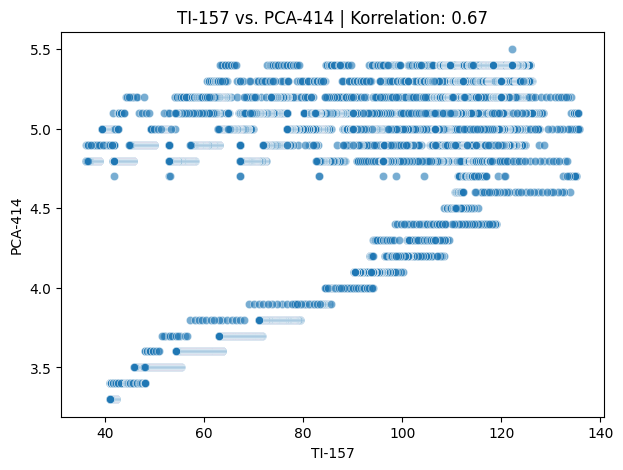

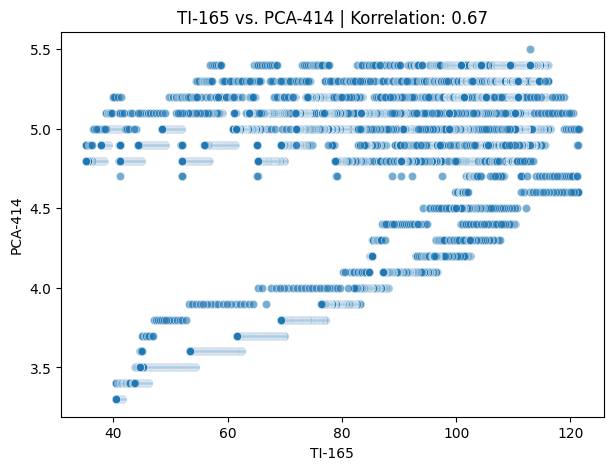

In [20]:
# ============================================================
# 8.2 Scatterplots der stärksten Korrelationen
# ============================================================

top_pairs = corr_pairs.head(10)

for _, row in top_pairs.iterrows():
    x_col = row["feature_1"]
    y_col = row["feature_2"]
    corr_value = row["correlation"]

    plt.figure(figsize=(7, 5))
    sns.scatterplot(data=df, x=x_col, y=y_col, alpha=0.6)
    plt.title(f"{x_col} vs. {y_col} | Korrelation: {corr_value:.2f}")
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.show()

In [21]:
# ============================================================
# 9. Zeitreihe vorbereiten
# ============================================================

df = df.copy()

# Datumsspalte in datetime umwandeln
df["Datum"] = pd.to_datetime(df["Datum"])

# Nach Datum sortieren
df = df.sort_values("Datum")

# Datum als Index setzen
df = df.set_index("Datum")

df.head()

,LI-117,LISA-103,TI-158,TI-165,TI-157,PCA-414,PA-411,TIZA-164,MI-156,TIC-160
Datum,,,,,,,,,,
2026-03-01 00:00:00,8,0.53,129.5,102.8,111.7,5.0,4.5,82.3,32.5,23.4
2026-03-01 00:00:10,8,0.52,129.3,102.8,111.8,5.0,4.5,82.3,32.5,23.4
2026-03-01 00:00:20,8,0.50,129.2,102.9,111.8,5.0,4.5,82.3,32.5,23.4
2026-03-01 00:00:30,6,0.50,129.1,103.0,111.8,5.0,4.5,82.3,32.5,23.4
2026-03-01 00:00:40,8,0.52,128.9,103.0,111.8,5.0,4.5,82.3,32.5,23.4


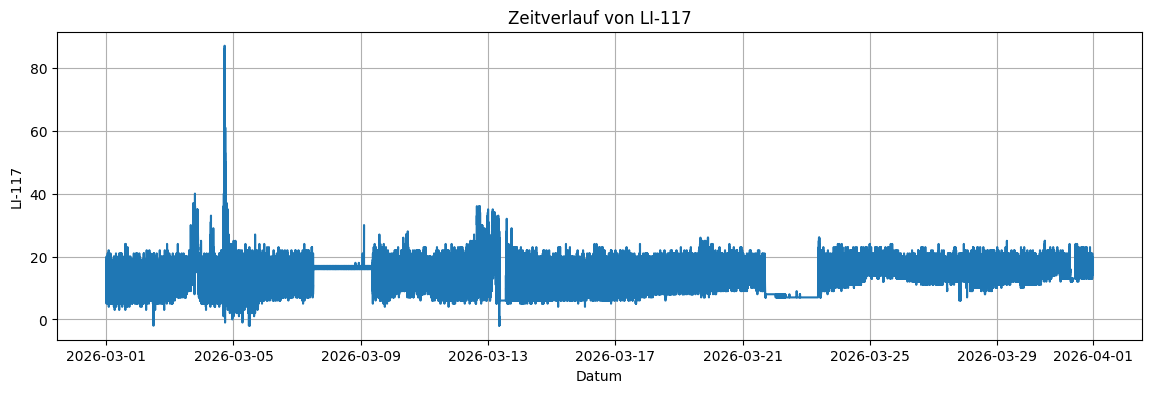

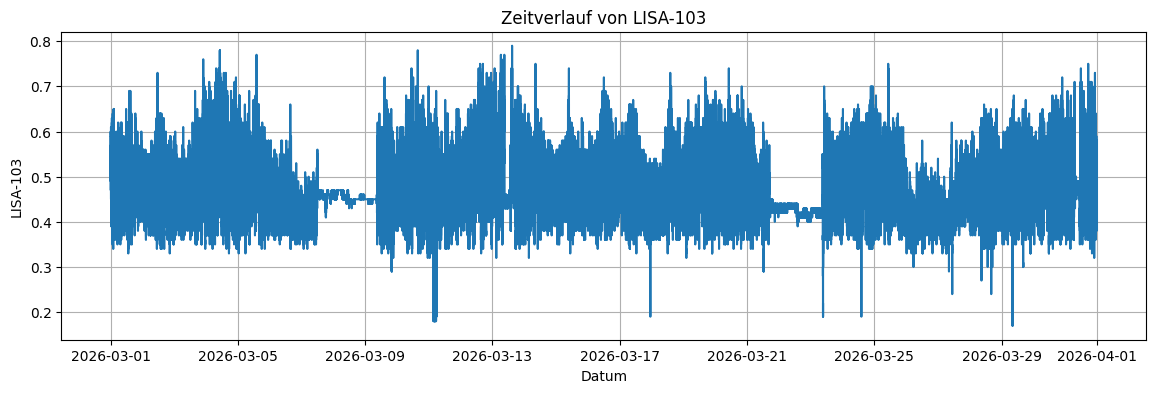

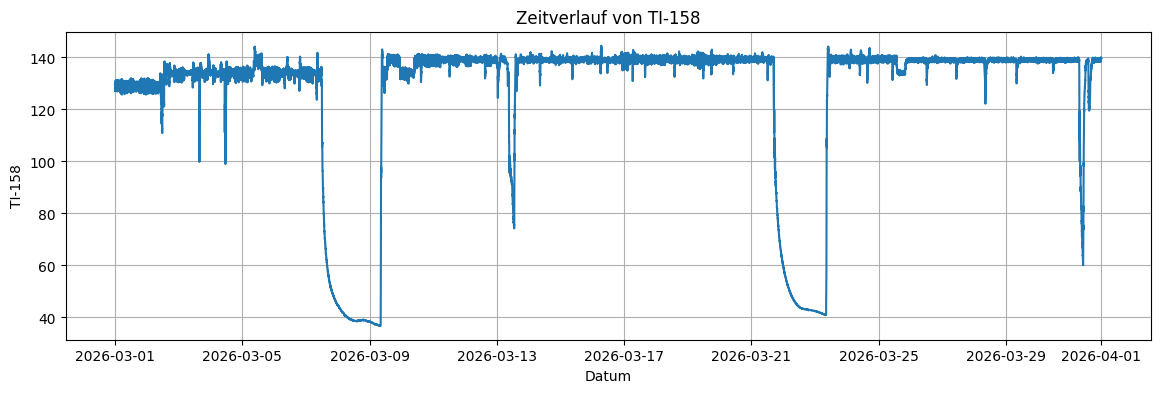

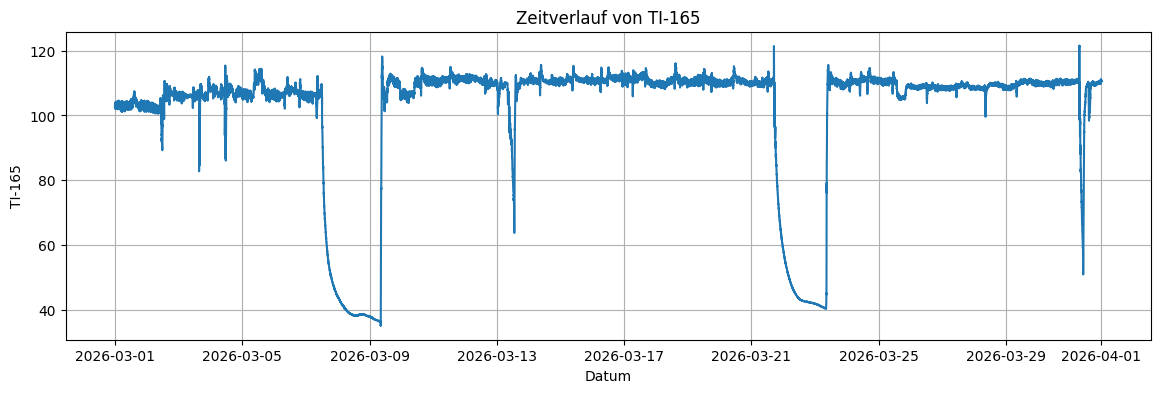

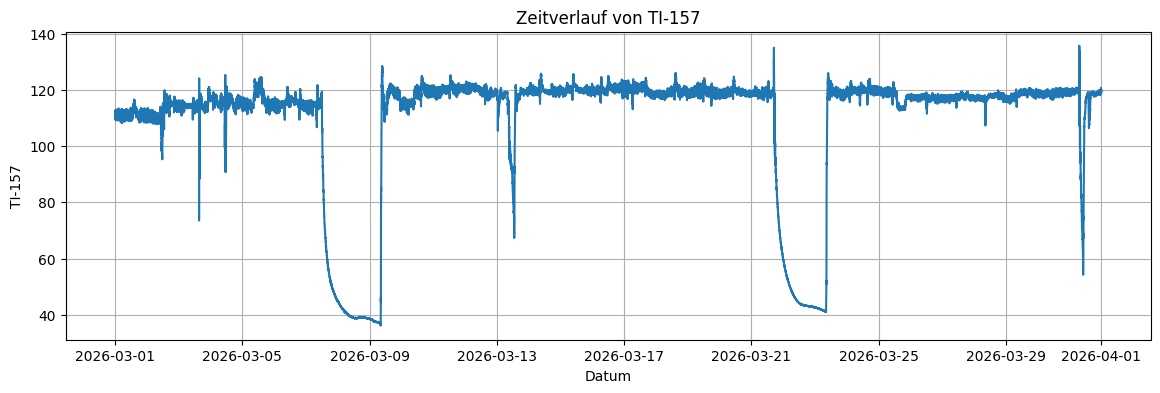

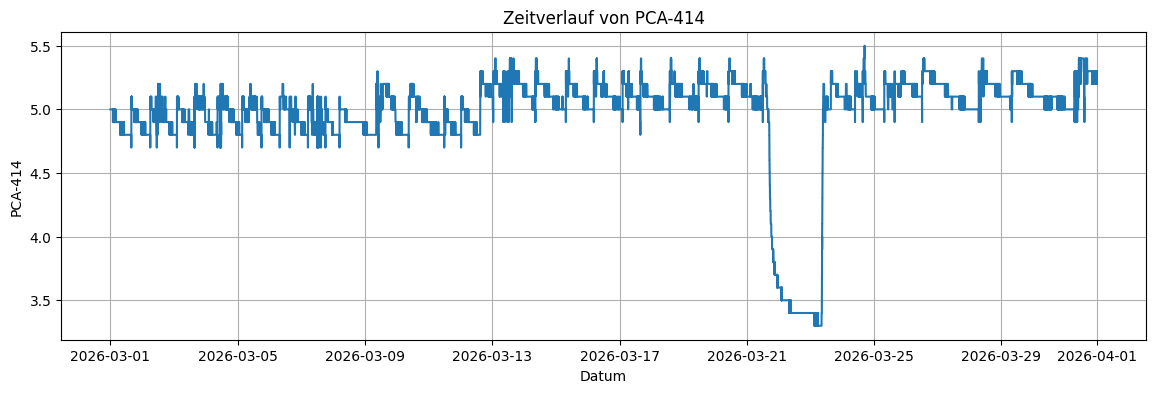

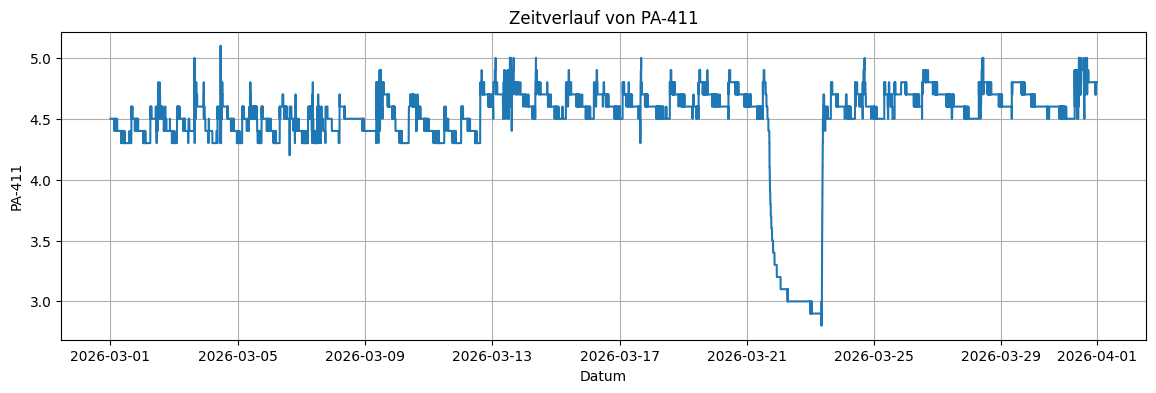

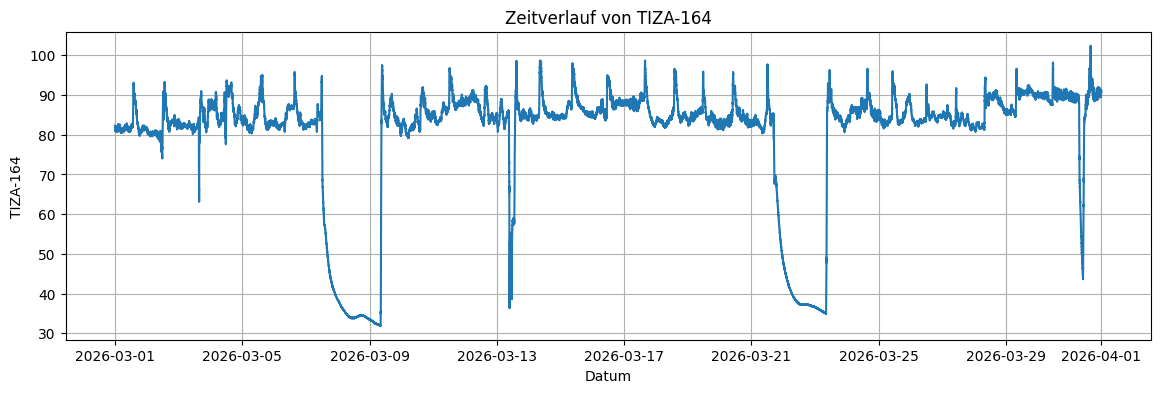

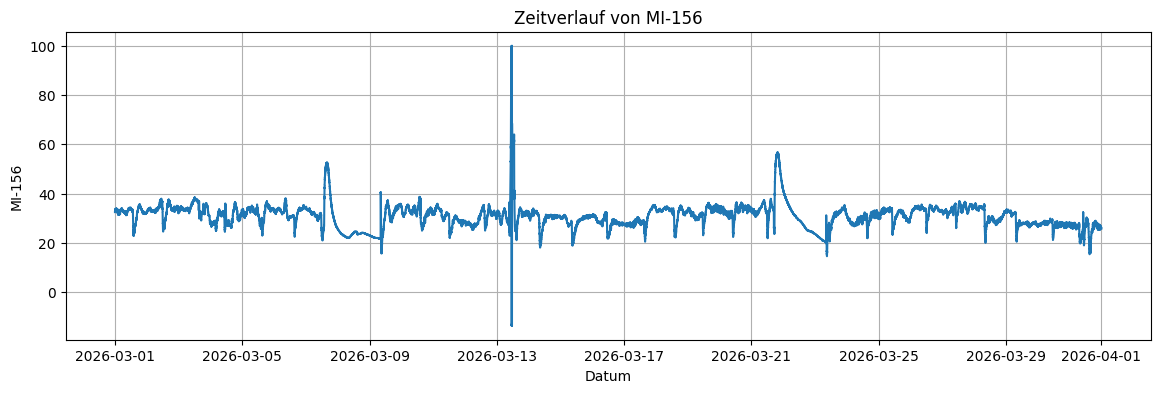

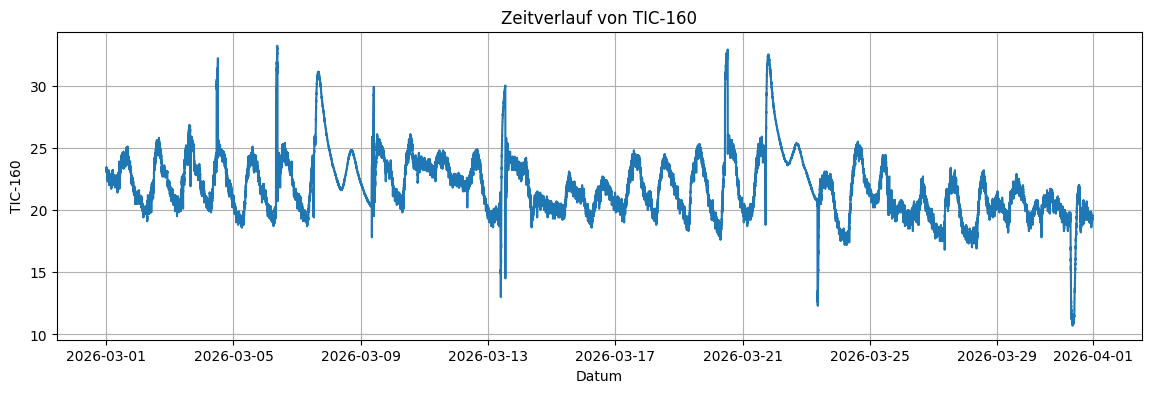

In [22]:
# ============================================================
# 9.2 Alle Parameter als einzelne Zeitreihen
# ============================================================

for col in num_cols:
    plt.figure(figsize=(14, 4))
    plt.plot(df.index, df[col])
    plt.title(f"Zeitverlauf von {col}")
    plt.xlabel("Datum")
    plt.ylabel(col)
    plt.grid(True)
    plt.show()